In [5]:
import pandas as pd

In [7]:
import numpy as np

In [9]:
import matplotlib.pyplot as plt

# Read Files

In [12]:
df_participant = pd.read_csv('Participant.csv')

In [14]:
df_participant

,participantID,name,height,weight,gender,dominantHand,experience,notes
0,P1,George,72,190.0,Male,R,5,tested in morning
1,P2,Maria,65,145.0,Female,L,3,NaN
2,P3,Jordan,168,175.0,Unknown,R,4,missing height
3,P4,Alex,68,199.0,Male,R,2,NaN
4,P5,Sam,168,185.5,Unknown,L,4,formatting issue
5,P6,Chris,70,165.0,Female,R,4,NaN
6,P7,Taylor,64,135.0,Female,L,1,NaN
7,P8,Jamie,69,180.0,Male,R,6,NaN
8,P9,Morgan,67,185.5,Unknown,R,5,NaN
9,P10,Casey,161,150.0,Female,L,2,NaN


In [16]:
df_trial = pd.read_csv('Trial.csv')
df_song = pd.read_csv('Song.csv')



In [18]:
df_trial

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce
0,T1,P1,1,No music,100,25,5.1,150,50,90
1,T1,P1,2,No music,105,27,5.4,155,52,93
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108
5,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112
6,T6,P6,1,120+ BPM,125,35,7.0,185,70,125
7,T6,P6,2,120+ BPM,130,36,7.2,190,72,128
8,T7,P7,1,60-120 BPM,99,21,4.9,145,48,84
9,T7,P7,2,60-120 BPM,101,23,5.2,149,50,86


In [20]:
df_song

,songID,songName,bpmRange,bpm
0,S1,Expresso,90,60-120 BPM
1,S2,Believer,120,60-120 BPM
2,S3,Eye of the Tiger,150,120+ BPM
3,S4,Thunder,80,60-120 BPM
4,S5,Lose Yourself,123,120+ BPM
5,S6,Don't Stop Me Now,170,120+ BPM
6,S7,Levels,128,120+ BPM
7,S8,Sweet Child O' Mine,95,60-120 BPM
8,S9,Radioactive,105,60-120 BPM
9,S10,Uptown Funk,115,60-120 BPM


In [22]:
df_song_and_trial=pd.DataFrame()

# Join song table and trial table

In [25]:
df_song_and_trial = pd.merge(
    df_trial,
    df_song,
    on="bpm",
    how="inner"
)

In [27]:
df_song_and_trial

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,songID,songName,bpmRange
0,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S1,Expresso,90
1,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S2,Believer,120
2,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S4,Thunder,80
3,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S8,Sweet Child O' Mine,95
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S9,Radioactive,105
5,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S10,Uptown Funk,115
6,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S1,Expresso,90
7,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S2,Believer,120
8,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S4,Thunder,80
9,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S8,Sweet Child O' Mine,95


## Check if there are any duplicate


In [30]:
df_song_and_trial.duplicated()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
dtype: bool

## Read the Pivot files

In [33]:
df_bpm = pd.read_csv('bpm_pivot.csv')
df_attempt=pd.read_csv('attempt_pivot.csv')
df_bpm

,bpm,AVERAGE of totalPunches,AVERAGE of accuracy,AVERAGE of maxForce,AVERAGE of minForce,AVERAGE of avgForce
0,<60 BPM,23.00,5.50,150.00,54.0,97.5
1,120+ BPM,35.50,7.10,187.50,71.0,126.5
2,60-120 BPM,26.25,5.65,157.75,55.0,97.5
3,No music,26.00,5.25,152.50,51.0,91.5
4,Grand Total,27.40,5.83,161.10,57.2,102.1


**This is used to get rid of the Grand Total**

In [36]:

df_bpm=df_bpm.iloc[:-1]
df_bpm

,bpm,AVERAGE of totalPunches,AVERAGE of accuracy,AVERAGE of maxForce,AVERAGE of minForce,AVERAGE of avgForce
0,<60 BPM,23.00,5.50,150.00,54.0,97.5
1,120+ BPM,35.50,7.10,187.50,71.0,126.5
2,60-120 BPM,26.25,5.65,157.75,55.0,97.5
3,No music,26.00,5.25,152.50,51.0,91.5


In [38]:
len(df_bpm)

4

In [40]:
df_bpm.index

RangeIndex(start=0, stop=4, step=1)

## Building chart for Total Punches & Accuracy by BPM Range

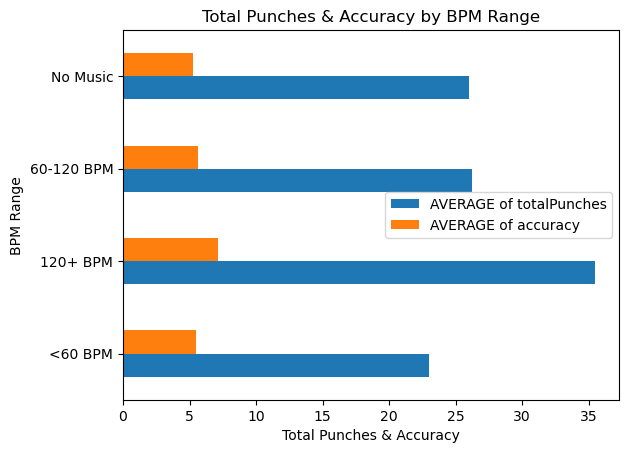

In [43]:
import matplotlib.pyplot as plt

df_chart_bpm = df_bpm[['AVERAGE of totalPunches', 'AVERAGE of accuracy']].plot.barh(
    xlabel="Total Punches & Accuracy",
    ylabel="BPM Range",
    title="Total Punches & Accuracy by BPM Range"
)

df_chart_bpm.set_yticks(range(4))
df_chart_bpm.set_yticklabels([
    '<60 BPM',
    '120+ BPM',
    '60-120 BPM',
    'No Music'
])

plt.show()

## Building chart for Total Punches & Accuracy by Attempt

In [46]:
df_attempt=df_attempt.iloc[:-1]
df_attempt

,attempt,AVERAGE of totalPunches,AVERAGE of accuracy,AVERAGE of maxForce,AVERAGE of minForce,AVERAGE of avgForce
0,1,26.4,5.82,159.6,57.4,99.0
1,2,28.4,5.84,162.6,57.0,105.2


[Text(0, 0, '1'), Text(0, 1, '2')]

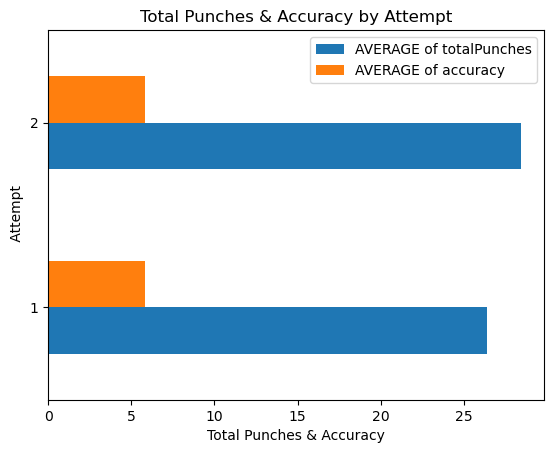

In [48]:
df_chart_attempt=df_attempt[['AVERAGE of totalPunches','AVERAGE of accuracy']].plot.barh(
        xlabel= "Total Punches & Accuracy",
        ylabel=" Attempt",
        title="Total Punches & Accuracy by Attempt"
)
df_chart_attempt.set_yticks(range(2))
df_chart_attempt.set_yticklabels(['1','2'])

## Trial Table


In [51]:
df_trial

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce
0,T1,P1,1,No music,100,25,5.1,150,50,90
1,T1,P1,2,No music,105,27,5.4,155,52,93
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108
5,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112
6,T6,P6,1,120+ BPM,125,35,7.0,185,70,125
7,T6,P6,2,120+ BPM,130,36,7.2,190,72,128
8,T7,P7,1,60-120 BPM,99,21,4.9,145,48,84
9,T7,P7,2,60-120 BPM,101,23,5.2,149,50,86


## Max Force by Participant and Attempt

In [54]:
df_chart_trial=df_trial.pivot( index='participantID',
    columns='attempt',
    values='maxForce')
df_chart_trial


attempt,1,2
participantID,,
P1,150,155
P4,148,152
P5,170,167
P6,185,190
P7,145,149


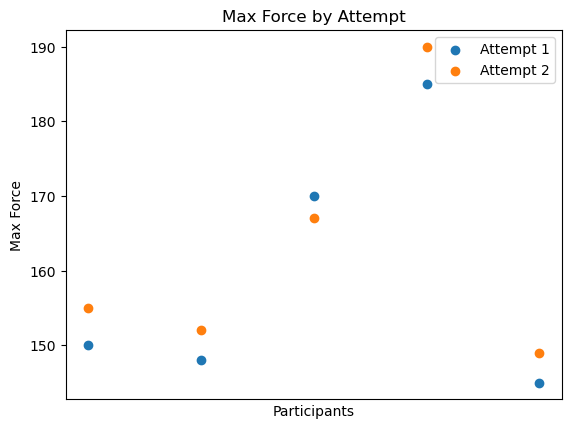

In [56]:
import matplotlib.pyplot as plt

plt.scatter(df_chart_trial.index, df_chart_trial[1], label='Attempt 1')
plt.scatter(df_chart_trial.index, df_chart_trial[2], label='Attempt 2')

plt.xlabel('Participants')
plt.ylabel('Max Force')
plt.title('Max Force by Attempt')
plt.legend()

plt.xticks([])  # Hide participant labels on the x-axis

plt.show()

## MinForce by Participant and Attempt


In [59]:
df_chart_trial_min=df_trial.pivot( index='participantID',
    columns='attempt',
    values='minForce')
df_chart_trial_min


attempt,1,2
participantID,,
P1,50,52
P4,59,49
P5,60,62
P6,70,72
P7,48,50


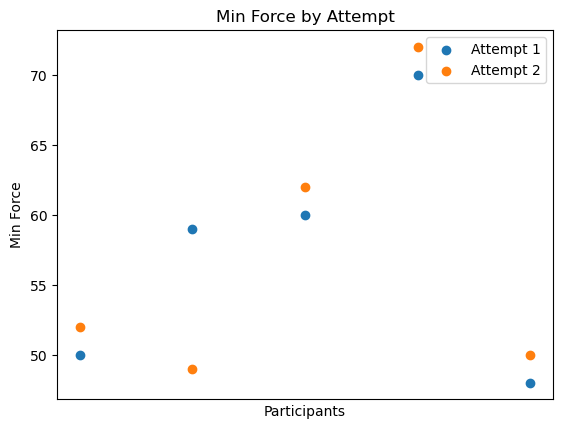

In [61]:
plt.scatter(df_chart_trial_min.index, df_chart_trial_min[1], label='Attempt 1')
plt.scatter(df_chart_trial_min.index, df_chart_trial_min[2], label='Attempt 2')

plt.xlabel('Participants')
plt.ylabel('Min Force')
plt.title('Min Force by Attempt')
plt.legend()

plt.xticks([])  # Hide participant labels on the x-axis

plt.show()

## AvgForce by Participant and Attempt

In [64]:
df_chart_trial_avg=df_trial.pivot( index='participantID',
    columns='attempt',
    values='avgForce')
df_chart_trial_avg


attempt,1,2
participantID,,
P1,90,93
P4,88,107
P5,108,112
P6,125,128
P7,84,86


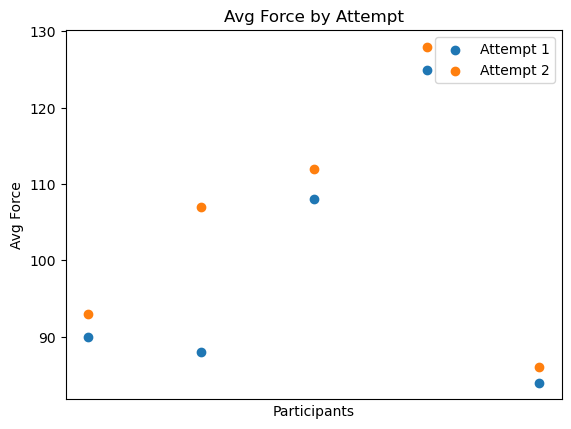

In [66]:
plt.scatter(df_chart_trial_avg.index, df_chart_trial_avg[1], label='Attempt 1')
plt.scatter(df_chart_trial_avg.index, df_chart_trial_avg[2], label='Attempt 2')

plt.xlabel('Participants')
plt.ylabel('Avg Force')
plt.title('Avg Force by Attempt')
plt.legend()

plt.xticks([])  # Hide participant labels on the x-axis

plt.show()

## Join Participant and Trial table

In [69]:
dfJoined = pd.merge(
    df_trial,
    df_participant,
    on="participantID",
    how="inner"
)

In [71]:
dfJoined.head()


,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,name,height,weight,gender,dominantHand,experience,notes
0,T1,P1,1,No music,100,25,5.1,150,50,90,George,72,190.0,Male,R,5,tested in morning
1,T1,P1,2,No music,105,27,5.4,155,52,93,George,72,190.0,Male,R,5,tested in morning
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88,Alex,68,199.0,Male,R,2,NaN
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107,Alex,68,199.0,Male,R,2,NaN
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,Sam,168,185.5,Unknown,L,4,formatting issue


In [73]:
dfJoined['exp'] = pd.cut(
    dfJoined['experience'],
    bins=3,
    labels=("none", "moderate", "expert")
)

In [75]:
dfJoined

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,name,height,weight,gender,dominantHand,experience,notes,exp
0,T1,P1,1,No music,100,25,5.1,150,50,90,George,72,190.0,Male,R,5,tested in morning,expert
1,T1,P1,2,No music,105,27,5.4,155,52,93,George,72,190.0,Male,R,5,tested in morning,expert
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88,Alex,68,199.0,Male,R,2,NaN,none
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107,Alex,68,199.0,Male,R,2,NaN,none
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,Sam,168,185.5,Unknown,L,4,formatting issue,expert
5,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,Sam,168,185.5,Unknown,L,4,formatting issue,expert
6,T6,P6,1,120+ BPM,125,35,7.0,185,70,125,Chris,70,165.0,Female,R,4,NaN,expert
7,T6,P6,2,120+ BPM,130,36,7.2,190,72,128,Chris,70,165.0,Female,R,4,NaN,expert
8,T7,P7,1,60-120 BPM,99,21,4.9,145,48,84,Taylor,64,135.0,Female,L,1,NaN,none
9,T7,P7,2,60-120 BPM,101,23,5.2,149,50,86,Taylor,64,135.0,Female,L,1,NaN,none


In [77]:
# Group By and Calculate the average of Maxforce

In [79]:
avg_maxforce=dfJoined.groupby(['attempt', 'exp'])['maxForce'].mean().reset_index()

/var/folders/43/2bccxmv52gz_5ft516psrl_80000gn/T/ipykernel_1772/1967420894.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_maxforce=dfJoined.groupby(['attempt', 'exp'])['maxForce'].mean().reset_index()


## Bar Chart for Average Max Force by Experience Group and Attempt

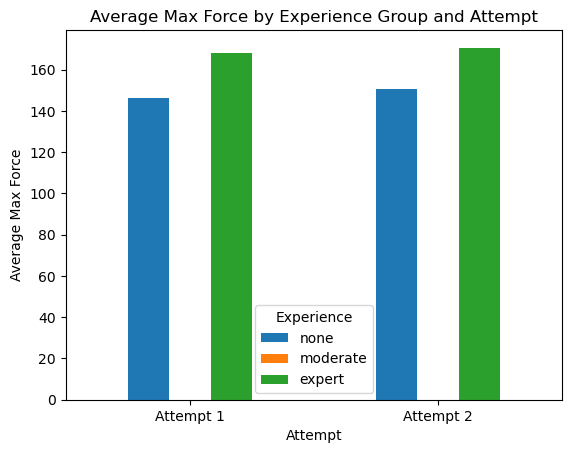

In [82]:
import matplotlib.pyplot as plt

df_chart_exp = avg_maxforce.pivot(
    index='attempt',
    columns='exp',
    values='maxForce'
)

df_chart_exp = df_chart_exp[['none', 'moderate', 'expert']]

df_chart_exp.plot.bar(
    xlabel='Attempt',
    ylabel='Average Max Force',
    title='Average Max Force by Experience Group and Attempt'
)

plt.xticks(
    ticks=[0, 1],
    labels=['Attempt 1', 'Attempt 2'],
    rotation=0
) 

plt.legend(title='Experience')
plt.show()

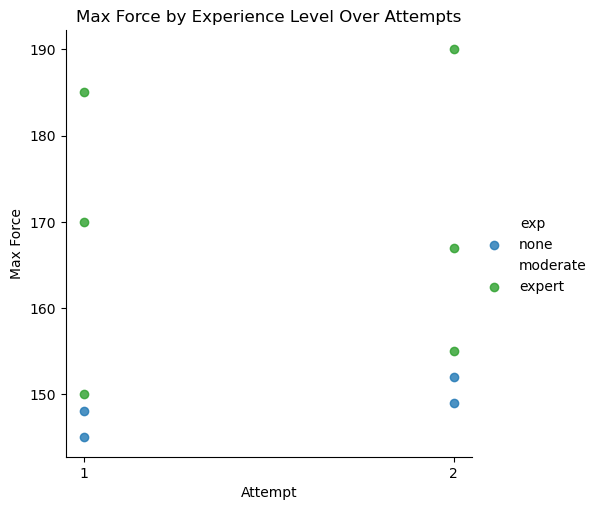

In [85]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lmplot(
    data=dfJoined,
    x='attempt',
    y='maxForce',
    hue='exp',
    fit_reg=False
)

plt.xlabel('Attempt')
plt.ylabel('Max Force')
plt.title('Max Force by Experience Level Over Attempts')
plt.xticks([1, 2])
plt.show()

# Create  charts using groupby to see how genders performed on given attempts

In [87]:
df_participant_trial= pd.merge(
    df_trial,
    df_participant,
    on="participantID",
    how="inner"
)

In [88]:
df_participant_trial.head()

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,name,height,weight,gender,dominantHand,experience,notes
0,T1,P1,1,No music,100,25,5.1,150,50,90,George,72,190.0,Male,R,5,tested in morning
1,T1,P1,2,No music,105,27,5.4,155,52,93,George,72,190.0,Male,R,5,tested in morning
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88,Alex,68,199.0,Male,R,2,NaN
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107,Alex,68,199.0,Male,R,2,NaN
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,Sam,168,185.5,Unknown,L,4,formatting issue


In [89]:
df_box = df_trial.groupby(
    ['participantID', 'attempt', 'maxForce']
).size().reset_index(name='count')

In [90]:
df_box

,participantID,attempt,maxForce,count
0,P1,1,150,1
1,P1,2,155,1
2,P4,1,148,1
3,P4,2,152,1
4,P5,1,170,1
5,P5,2,167,1
6,P6,1,185,1
7,P6,2,190,1
8,P7,1,145,1
9,P7,2,149,1


In [91]:
df_box['max_bins'] = ''

In [92]:
df_box.head()

,participantID,attempt,maxForce,count,max_bins
0,P1,1,150,1,
1,P1,2,155,1,
2,P4,1,148,1,
3,P4,2,152,1,
4,P5,1,170,1,


In [100]:
n = len(df_box)

In [102]:
for i in range(n):
    if df_box.iloc[i]['attempt'] == 2:
        current_max = df_box.iloc[i]['maxForce']
        previous_max = df_box.iloc[i-1]['maxForce']

        if current_max > previous_max:
            df_box.iloc[i, df_box.columns.get_loc('max_bins')] = 'improved'

        elif current_max < previous_max:
            df_box.iloc[i, df_box.columns.get_loc('max_bins')] = 'no improvement'

        else:
            df_box.iloc[i, df_box.columns.get_loc('max_bins')] = 'same'

In [104]:
df_box

,participantID,attempt,maxForce,count,max_bins
0,P1,1,150,1,
1,P1,2,155,1,improved
2,P4,1,148,1,
3,P4,2,152,1,improved
4,P5,1,170,1,
5,P5,2,167,1,no improvement
6,P6,1,185,1,
7,P6,2,190,1,improved
8,P7,1,145,1,
9,P7,2,149,1,improved


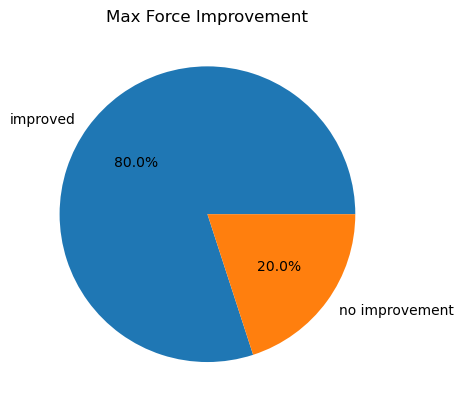

In [106]:
import matplotlib.pyplot as plt

auto_size = df_box['max_bins'].value_counts()
auto_size = auto_size[auto_size.index != '']

auto_size.plot.pie(
    autopct='%1.1f%%',
    title='Max Force Improvement',
    ylabel=''
)

plt.show()

In [108]:
df_box['max_bins']

0                  
1          improved
2                  
3          improved
4                  
5    no improvement
6                  
7          improved
8                  
9          improved
Name: max_bins, dtype: object

# Data Analysis Pt.3

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt

In [113]:
from wordcloud import WordCloud

In [115]:
from scipy.stats import pearsonr

## Graph the MaxForce Regression By BPM

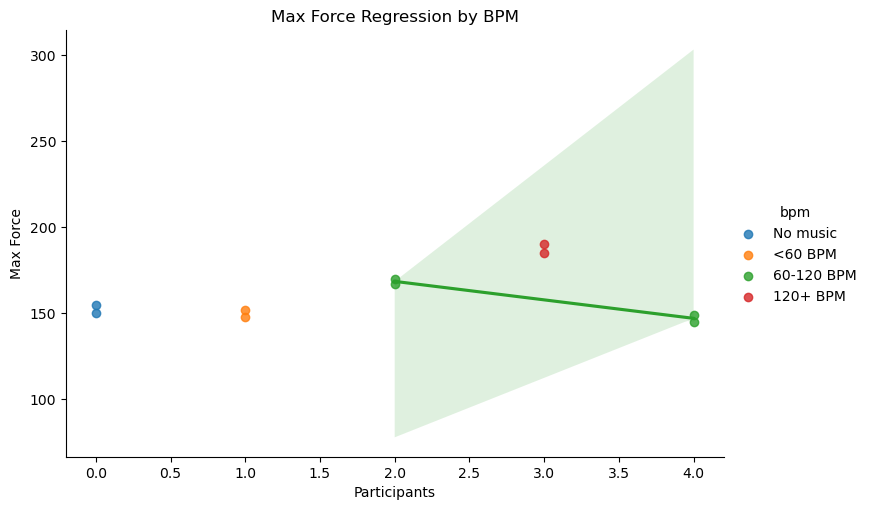

In [118]:


dfJoined['participant_num'] = (
    dfJoined['participantID'].astype('category').cat.codes
)

sns.lmplot(
    data=dfJoined,
    x='participant_num',
    y='maxForce',
    hue='bpm',
    height=5,
    aspect=1.5
)

plt.title('Max Force Regression by BPM')
plt.xlabel('Participants')
plt.ylabel('Max Force')
plt.show()

## Graph the Accuracy Regression By BPM

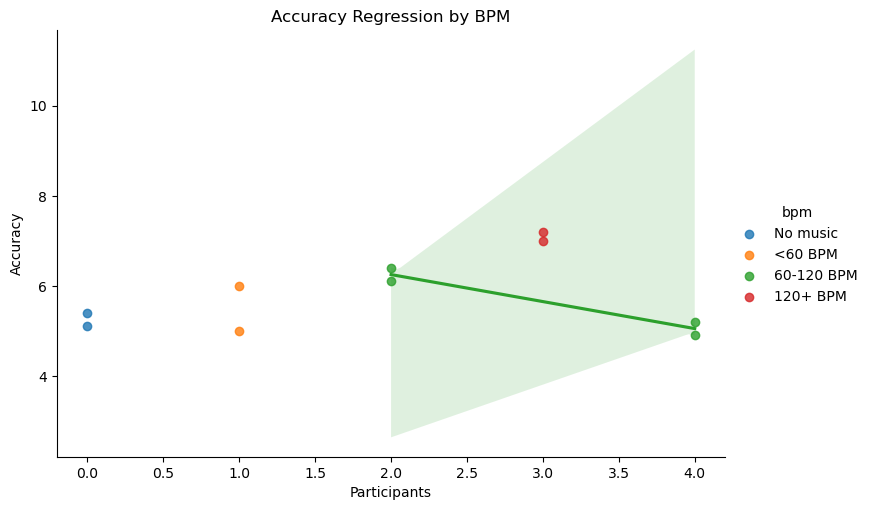

In [121]:

sns.lmplot(
    data=dfJoined,
    x='participant_num',
    y='accuracy',
    hue='bpm',
    height=5,
    aspect=1.5
)

plt.title('Accuracy Regression by BPM')
plt.xlabel('Participants')
plt.ylabel('Accuracy')
plt.show()

## Graph the Max Force Regression By Attempt

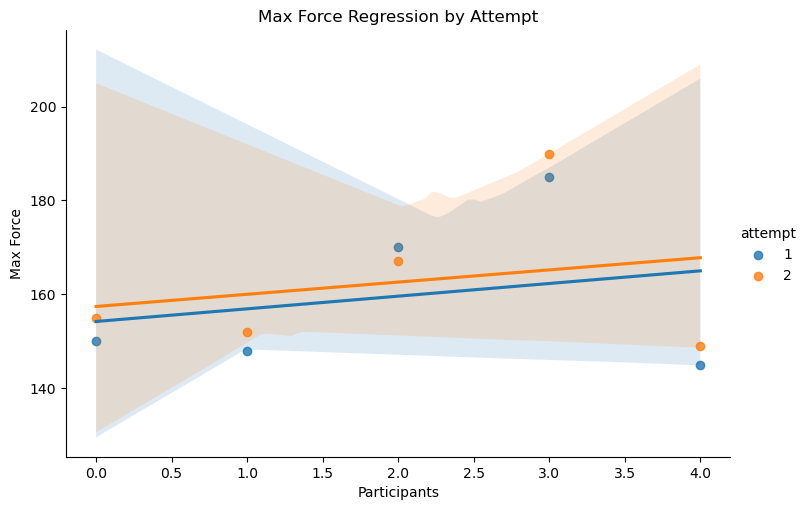

In [124]:
sns.lmplot(
    data=dfJoined,
    x='participant_num',
    y='maxForce',
    hue='attempt',
    height=5,
    aspect=1.5
)

plt.title('Max Force Regression by Attempt')
plt.xlabel('Participants')
plt.ylabel('Max Force')
plt.show()

## Graph the Accuracy Regression By Attempt

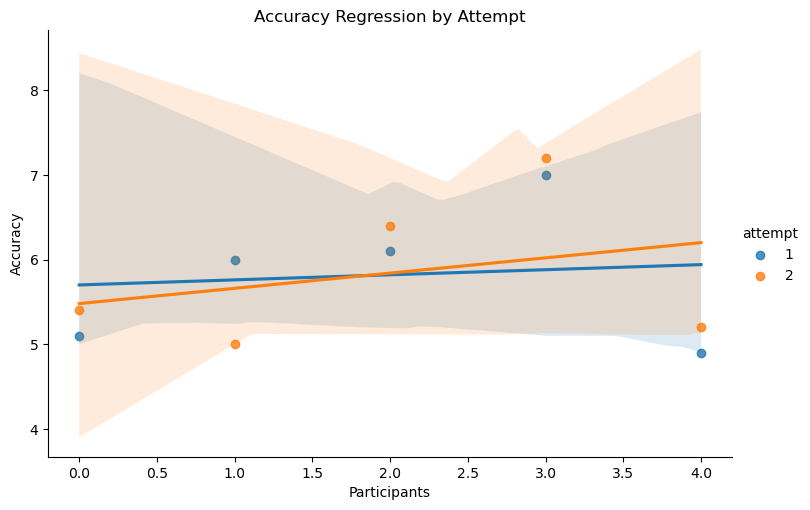

In [127]:
sns.lmplot(
    data=dfJoined,
    x='participant_num',
    y='accuracy',
    hue='attempt',
    height=5,
    aspect=1.5
)

plt.title('Accuracy Regression by Attempt')
plt.xlabel('Participants')
plt.ylabel('Accuracy')
plt.show()

In [129]:
## Using pearsonr to calculate the p-value

In [131]:
from scipy.stats import pearsonr

result = []

for bpm, group in dfJoined.groupby('bpm'):
    # Relationship between participants and maxForce
    r_max, p_max = pearsonr(
        group['participant_num'],
        group['maxForce']
    )

    # Relationship between participants and accuracy
    r_acc, p_acc = pearsonr(
        group['participant_num'],
        group['accuracy']
    )

    result.append({
        'BPM': bpm,
        'MaxForce_r': r_max,
        'MaxForce_p-value': p_max,
        'Accuracy_r': r_acc,
        'Accuracy_p-value': p_acc
    })

df_result_bpm = pd.DataFrame(result)
print(df_result_bpm)

          BPM  MaxForce_r  MaxForce_p-value  Accuracy_r  Accuracy_p-value
0    120+ BPM         NaN               NaN         NaN               NaN
1  60-120 BPM   -0.986747          0.013253   -0.970143          0.029857
2     <60 BPM         NaN               NaN         NaN               NaN
3    No music         NaN               NaN         NaN               NaN


/var/folders/43/2bccxmv52gz_5ft516psrl_80000gn/T/ipykernel_1772/3308323658.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_max, p_max = pearsonr(
/var/folders/43/2bccxmv52gz_5ft516psrl_80000gn/T/ipykernel_1772/3308323658.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_acc, p_acc = pearsonr(


In [134]:
result_attempt = []

for attempt, group in dfJoined.groupby('attempt'):
    # Relationship between participants and maxForce
    r_max, p_max = pearsonr(
        group['participant_num'],
        group['maxForce']
    )

    # Relationship between participants and accuracy
    r_acc, p_acc = pearsonr(
        group['participant_num'],
        group['accuracy']
    )

    result_attempt.append({
        'Attempt': attempt,
        'MaxForce_r': r_max,
        'MaxForce_p-value': p_max,
        'Accuracy_r': r_acc,
        'Accuracy_p-value': p_acc
    })

df_result_attempt = pd.DataFrame(result_attempt)
print(df_result_attempt)

   Attempt  MaxForce_r  MaxForce_p-value  Accuracy_r  Accuracy_p-value
0        1    0.247176          0.688520    0.112037          0.857649
1        2    0.245109          0.691072    0.305480          0.617188


## Perform some math to show how large of an improvement is made between given attempts

In [137]:
df_force = dfJoined.groupby(
    ['participantID', 'attempt'],
    as_index=False
).agg({
    'maxForce': 'mean',
    'avgForce': 'mean'
})

print(df_force)

  participantID  attempt  maxForce  avgForce
0            P1        1     150.0      90.0
1            P1        2     155.0      93.0
2            P4        1     148.0      88.0
3            P4        2     152.0     107.0
4            P5        1     170.0     108.0
5            P5        2     167.0     112.0
6            P6        1     185.0     125.0
7            P6        2     190.0     128.0
8            P7        1     145.0      84.0
9            P7        2     149.0      86.0


In [139]:
# Calculate the force ratio for each participant
df_force['force_ratio'] = (
    df_force['maxForce'] / df_force['avgForce']
)

print(df_force)

  participantID  attempt  maxForce  avgForce  force_ratio
0            P1        1     150.0      90.0     1.666667
1            P1        2     155.0      93.0     1.666667
2            P4        1     148.0      88.0     1.681818
3            P4        2     152.0     107.0     1.420561
4            P5        1     170.0     108.0     1.574074
5            P5        2     167.0     112.0     1.491071
6            P6        1     185.0     125.0     1.480000
7            P6        2     190.0     128.0     1.484375
8            P7        1     145.0      84.0     1.726190
9            P7        2     149.0      86.0     1.732558


In [141]:
df_pivot = df_force.pivot(
    index='participantID',
    columns='attempt',
    values=['maxForce', 'avgForce', 'force_ratio']
)

print(df_pivot)

              maxForce        avgForce        force_ratio          
attempt              1      2        1      2           1         2
participantID                                                      
P1               150.0  155.0     90.0   93.0    1.666667  1.666667
P4               148.0  152.0     88.0  107.0    1.681818  1.420561
P5               170.0  167.0    108.0  112.0    1.574074  1.491071
P6               185.0  190.0    125.0  128.0    1.480000  1.484375
P7               145.0  149.0     84.0   86.0    1.726190  1.732558


In [143]:
df_pivot['ratio_change'] = (
    df_pivot[('force_ratio', 2)]
    - df_pivot[('force_ratio', 1)]
)

print(df_pivot)

              maxForce        avgForce        force_ratio            \
attempt              1      2        1      2           1         2   
participantID                                                         
P1               150.0  155.0     90.0   93.0    1.666667  1.666667   
P4               148.0  152.0     88.0  107.0    1.681818  1.420561   
P5               170.0  167.0    108.0  112.0    1.574074  1.491071   
P6               185.0  190.0    125.0  128.0    1.480000  1.484375   
P7               145.0  149.0     84.0   86.0    1.726190  1.732558   

              ratio_change  
attempt                     
participantID               
P1                0.000000  
P4               -0.261257  
P5               -0.083003  
P6                0.004375  
P7                0.006368  


In [145]:
print(df_pivot['ratio_change'].mean())

-0.06670348326257373


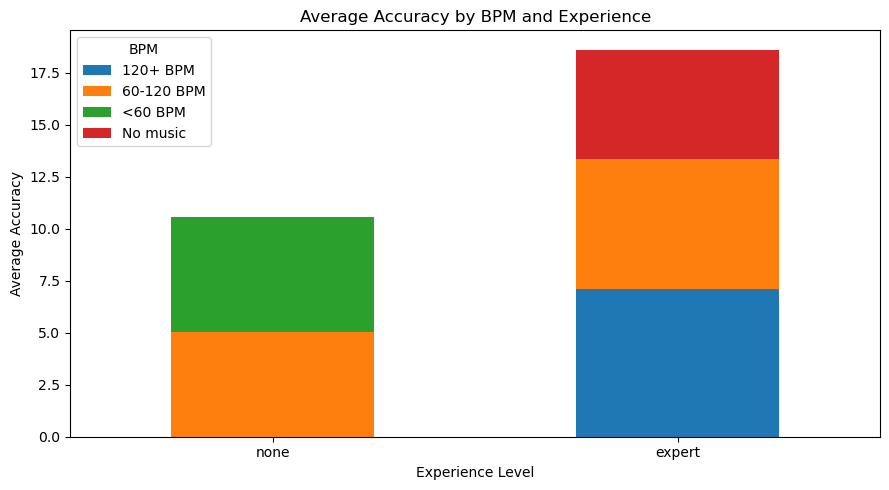

In [148]:
import pandas as pd
import matplotlib.pyplot as plt

# Group by experience and BPM
df_bpm_exp = dfJoined.groupby(
    ['exp', 'bpm'],
    observed=True
)['accuracy'].mean().reset_index()

# Pivot so each BPM category becomes a column
df_bpm_pivot = df_bpm_exp.pivot(
    index='exp',
    columns='bpm',
    values='accuracy'
)

# Create stacked bar chart
df_bpm_pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Average Accuracy by BPM and Experience')
plt.xlabel('Experience Level')
plt.ylabel('Average Accuracy')
plt.xticks(rotation=0)
plt.legend(title='BPM')
plt.tight_layout()
plt.show()

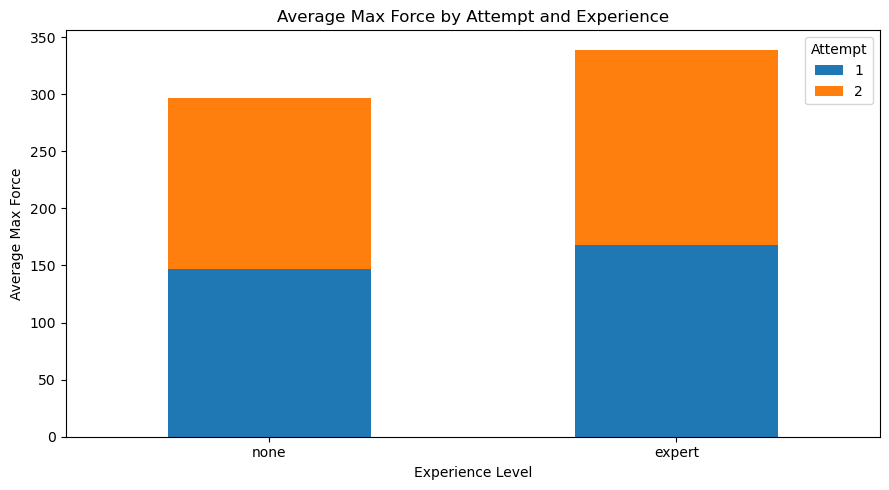

In [150]:
# Group by experience and attempt
df_attempt_exp = dfJoined.groupby(
    ['exp', 'attempt'],
    observed=True
)['maxForce'].mean().reset_index()

# Pivot so each attempt becomes a column
df_attempt_pivot = df_attempt_exp.pivot(
    index='exp',
    columns='attempt',
    values='maxForce'
)

# Create stacked bar chart
df_attempt_pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Average Max Force by Attempt and Experience')
plt.xlabel('Experience Level')
plt.ylabel('Average Max Force')
plt.xticks(rotation=0)
plt.legend(title='Attempt')
plt.tight_layout()
plt.show()

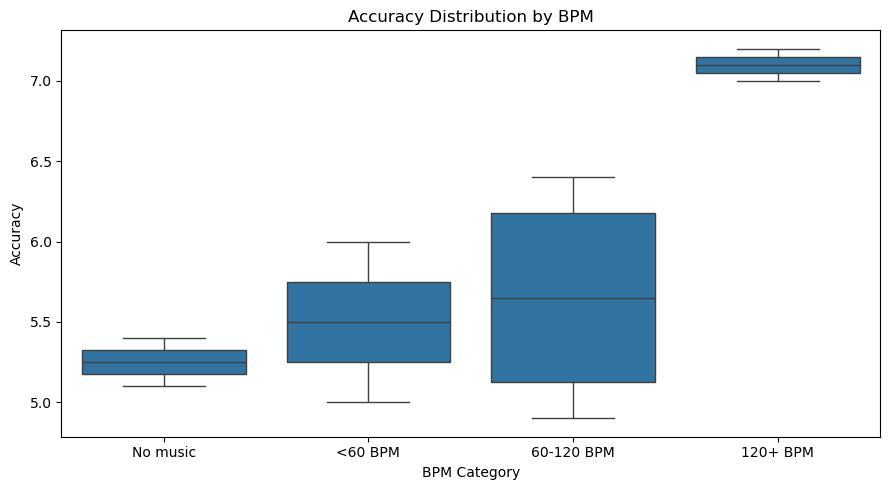

In [153]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=dfJoined,
    x='bpm',
    y='accuracy'
)

plt.title('Accuracy Distribution by BPM')
plt.xlabel('BPM Category')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()

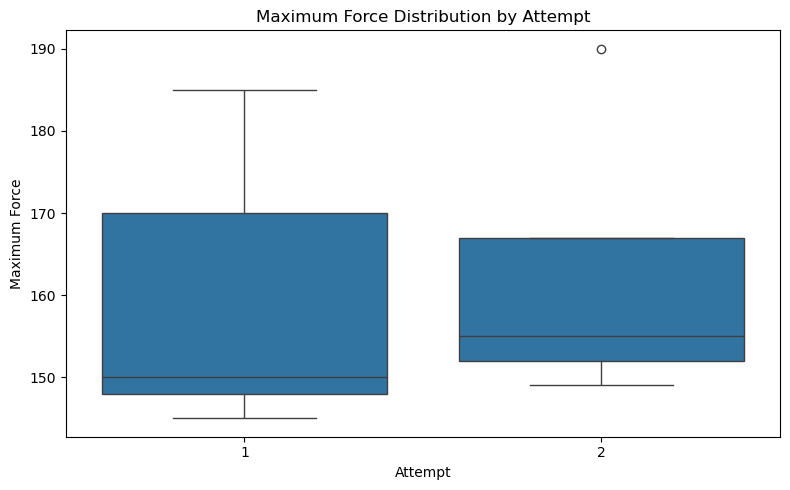

In [156]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=dfJoined,
    x='attempt',
    y='maxForce'
)

plt.title('Maximum Force Distribution by Attempt')
plt.xlabel('Attempt')
plt.ylabel('Maximum Force')
plt.tight_layout()
plt.show()

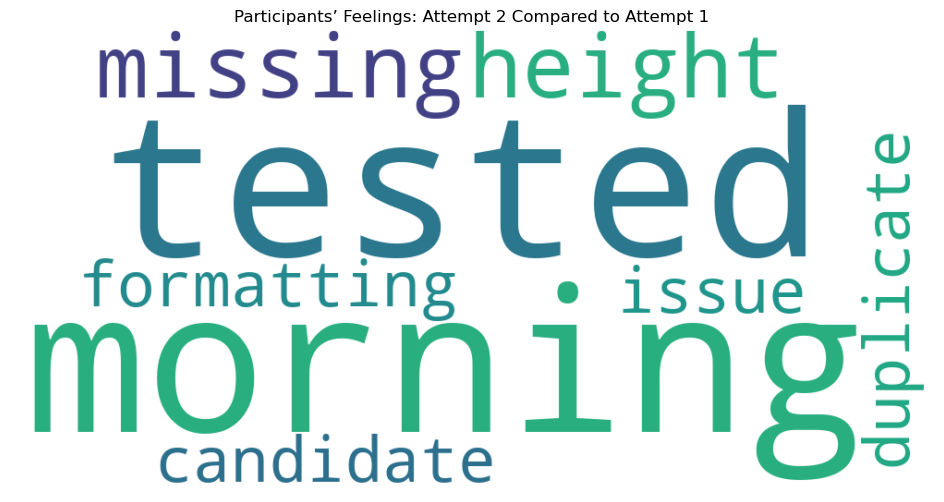

In [159]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt


# Combine all participants' notes into one text
text = " ".join(
    df_participant['notes'].dropna().astype(str)
)

# Generate the word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    stopwords=STOPWORDS,
    colormap='viridis'
).generate(text)

# Display the word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Participants’ Feelings: Attempt 2 Compared to Attempt 1')
plt.show()